# B6: Sentiment Analysis and Text Classification Pipeline

Build a complete sentiment pipeline: preprocessing and TF-IDF features, a Logistic Regression / Naive Bayes classifier, classification into positive / negative, evaluation with accuracy, precision, recall, F1 and the confusion matrix, and analysis with suggested improvements.

**Dataset:** IMDB Movie Reviews (50,000) and the Twitter sentiment samples in NLTK (10,000 tweets)

In [2]:
# scikit-learn : TF-IDF, models, metrics
# nltk         : the Twitter samples
!pip install -q scikit-learn nltk pandas matplotlib

In [3]:
import re
import pandas as pd, matplotlib.pyplot as plt
import nltk
nltk.download("twitter_samples", quiet=True)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

## IMDB reviews

In [4]:
imdb = pd.read_csv("https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv")
x = imdb["review"]
y = imdb["sentiment"]
print(y.value_counts())
x[0][:300]

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru"

## (a) Preprocessing and TF-IDF

In [5]:
def clean(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)          # HTML line breaks
    text = re.sub(r"[^a-z' ]", " ", text)            # keep letters and apostrophes only
    return text

print(clean(x[0])[:300])

one of the other reviewers has mentioned that after watching just   oz episode you'll be hooked  they are right  as this is exactly what happened with me   the first thing that struck me about oz was its brutality and unflinching scenes of violence  which set in right from the word go  trust me  thi


In [6]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

tfidf = TfidfVectorizer(preprocessor=clean, stop_words="english", min_df=2)
x_train_vec = tfidf.fit_transform(x_train)
x_test_vec = tfidf.transform(x_test)
x_train_vec.shape

(40000, 53698)

## (b) Models and (c) classification

In [7]:
lr = LogisticRegression(max_iter=1000).fit(x_train_vec, y_train)
nb_model = MultinomialNB().fit(x_train_vec, y_train)

new = ["One of the best films of the year, the acting is superb.",
       "Two hours of my life I will never get back.",
       "The songs were nice but the story was boring."]
pd.DataFrame({"review": new, "Logistic Regression": lr.predict(tfidf.transform(new)),
              "Naive Bayes": nb_model.predict(tfidf.transform(new))})

,review,Logistic Regression,Naive Bayes
0,"One of the best films of the year, the acting ...",positive,positive
1,Two hours of my life I will never get back.,positive,negative
2,The songs were nice but the story was boring.,negative,negative


## (d) Evaluation

In [8]:
y_pred_lr = lr.predict(x_test_vec)
y_pred_nb = nb_model.predict(x_test_vec)
print("LOGISTIC REGRESSION"); print(classification_report(y_test, y_pred_lr))
print("NAIVE BAYES"); print(classification_report(y_test, y_pred_nb))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      5000
    positive       0.89      0.91      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000

NAIVE BAYES


              precision    recall  f1-score   support

    negative       0.86      0.88      0.87      5000
    positive       0.88      0.86      0.87      5000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



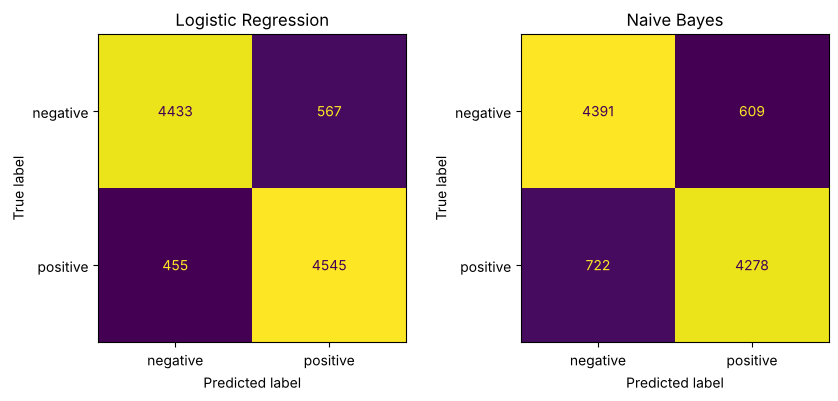

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, ax=ax[0], colorbar=False)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nb, ax=ax[1], colorbar=False)
ax[0].set_title("Logistic Regression"); ax[1].set_title("Naive Bayes"); plt.show()

## (e) Analyse the model

In [10]:
weights = pd.Series(lr.coef_[0], index=tfidf.get_feature_names_out()).sort_values()
print("most negative words:", list(weights.index[:10]))
print("most positive words:", list(weights.index[-10:]))

most negative words: ['worst', 'bad', 'waste', 'awful', 'boring', 'poor', 'terrible', 'worse', 'dull', 'poorly']
most positive words: ['fun', 'favorite', 'enjoyed', 'loved', 'amazing', 'wonderful', 'perfect', 'best', 'excellent', 'great']


In [11]:
# reviews the model got wrong
wrong = x_test[y_pred_lr != y_test]
print(len(wrong), "wrong out of", len(x_test))
for text in wrong.head(3):
    print("-", clean(text)[:250], "...")

1022 wrong out of 10000
- the story of the bride fair is an amusing and engaging one  and it is to the filmmaker's credit that he sets out to portray rural minnesotans with the same respect ordinarily reserved for coast dwellers  it is weird  though  to find an independent mo ...
- this movie is really wack  there is really nothing nice i can say about it  besides the moral truth expressed in the film's climax concerning people in the neighborhood participating in the fight against crime  besides all that  the film had nothing  ...
- i admit creating great expectations before watching because some friends mentioned it  and they are not pervs   as a must see  and it is a must see  just don't expect to see something outbreaking   the freudian psychoanalyzes are interesting in many  ...


In [12]:
# "not" is a stop word, so it was removed
print("'not' in stop words:", "not" in tfidf.get_stop_words())
print(lr.predict(tfidf.transform(["not good", "not bad"])))

'not' in stop words: True
['positive' 'negative']


## Improvements

Try three changes, one at a time, on the same split:
1. keep stop words (so "not", "no" stay),
2. add word pairs (bigrams), so "not good" becomes one feature,
3. a larger C (less regularisation).

In [13]:
def score(vectorizer, model):
    xtr = vectorizer.fit_transform(x_train); xte = vectorizer.transform(x_test)
    pred = model.fit(xtr, y_train).predict(xte)
    return {"accuracy": accuracy_score(y_test, pred), "f1": f1_score(y_test, pred, pos_label="positive")}

experiments = {
    "baseline (stop words removed)": (TfidfVectorizer(preprocessor=clean, stop_words="english", min_df=2), LogisticRegression(max_iter=1000)),
    "1. keep stop words": (TfidfVectorizer(preprocessor=clean, min_df=2), LogisticRegression(max_iter=1000)),
    "2. + bigrams": (TfidfVectorizer(preprocessor=clean, min_df=2, ngram_range=(1, 2)), LogisticRegression(max_iter=1000)),
    "3. + C=10": (TfidfVectorizer(preprocessor=clean, min_df=2, ngram_range=(1, 2)), LogisticRegression(C=10, max_iter=1000)),
}
pd.DataFrame({name: score(v, m) for name, (v, m) in experiments.items()}).T.round(4)

,accuracy,f1
baseline (stop words removed),0.8978,0.8989
1. keep stop words,0.8998,0.9003
2. + bigrams,0.9047,0.9054
3. + C=10,0.9191,0.9195


## Twitter dataset

The tweets were labelled using emoticons: tweets with :) are positive, with :( negative. If we leave the emoticons in, the model just learns them, so we remove them first.

In [14]:
from nltk.corpus import twitter_samples
pos = twitter_samples.strings("positive_tweets.json")
neg = twitter_samples.strings("negative_tweets.json")
tweets = pd.DataFrame({"text": pos + neg, "label": ["positive"] * len(pos) + ["negative"] * len(neg)})

def clean_tweet(t):
    t = re.sub(r"https?://\S+|@\w+", " ", t)              # links and @mentions
    t = re.sub(r"[:;=]-?[()DPp/]+|<3", " ", t)             # emoticons
    return clean(t)

tweets["clean"] = tweets["text"].map(clean_tweet)
tweets.sample(3, random_state=1)

,text,label,clean
9953,PAP of your spirit animal? — no i dont have :(...,negative,pap of your spirit animal no i dont have
3850,@iamsrk Lol. That look's like a scary room! Gh...,positive,lol that look's like a scary room ghost st...
4962,"@keab42 I rang in sick yesterday, then told th...",positive,i rang in sick yesterday then told them i'd...


In [15]:
xt_train, xt_test, yt_train, yt_test = train_test_split(tweets["clean"], tweets["label"], test_size=0.2,
                                                        random_state=42, stratify=tweets["label"])
tfidf_t = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
xt_train_vec = tfidf_t.fit_transform(xt_train)
xt_test_vec = tfidf_t.transform(xt_test)

for name, model in [("Logistic Regression", LogisticRegression(max_iter=1000)), ("Naive Bayes", MultinomialNB())]:
    pred = model.fit(xt_train_vec, yt_train).predict(xt_test_vec)
    print(name); print(classification_report(yt_test, pred))

Logistic Regression
              precision    recall  f1-score   support

    negative       0.76      0.80      0.78      1000
    positive       0.79      0.75      0.77      1000

    accuracy                           0.77      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.77      0.77      0.77      2000

Naive Bayes
              precision    recall  f1-score   support

    negative       0.75      0.82      0.79      1000
    positive       0.81      0.73      0.76      1000

    accuracy                           0.78      2000
   macro avg       0.78      0.78      0.77      2000
weighted avg       0.78      0.78      0.77      2000



In [16]:
# what happens if the emoticons are NOT removed
xr_train, xr_test, yr_train, yr_test = train_test_split(tweets["text"], tweets["label"], test_size=0.2, random_state=42, stratify=tweets["label"])
v = TfidfVectorizer(token_pattern=r"[:;=]-?[()DPp]|\w+")      # keep :) and :( as tokens
pred = LogisticRegression(max_iter=1000).fit(v.fit_transform(xr_train), yr_train).predict(v.transform(xr_test))
print(f"accuracy with emoticons left in: {accuracy_score(yr_test, pred):.3f}  <- the model only reads the smileys")

accuracy with emoticons left in: 0.998  <- the model only reads the smileys


## Analysis and suggested improvements
- On IMDB both models reach high accuracy; Logistic Regression is a little better than Naive Bayes. Precision and recall are balanced because the classes are balanced.
- The strongest words make sense (worst, waste, awful vs excellent, perfect, great).
- Errors: mixed reviews, sarcasm, plot summaries full of negative words, and negation ("not good"), which the stop-word list destroys.
- Keeping stop words, adding bigrams and a larger C each change the score; the table shows which helped here.
- Tweets are much harder: short and informal, and the emoticons that defined the labels had to be removed.
- Further improvements: handle negation explicitly, use word embeddings, or fine-tune BERT (practical B7).